In [45]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import seaborn as sns

In [ ]:
#불러오기
file_path = 'vowel60.csv'
data = pd.read_csv(file_path, encoding='utf-16')

data.head()

,pre,V,post,length,devoicing,devoiced
0,l,ɨ,m,0.06000,0.0,False
1,m,ɨ,n,0.10000,0.0,False
2,s,ə,s',0.07000,0.0,False
3,s',a,l,0.10935,0.0,False
4,m,a,n,0.10234,0.0,False


In [48]:
vowels = set(data['V'])
consonants = set(data['pre'])

In [ ]:
# feature 조건에 맞는 음소 목록 정의
high_vowels = {'i', 'ɨ', 'u'}   #고모음
spr_glottis_continuant = {'pʰ', 'tʰ', 'kʰ', 'tɕʰ', 's', 's\'', 'h'} #[+spread glottis, +continuant]
spr_glottis_noncontinuant = {'pʰ', 'tʰ', 'kʰ', 'tɕʰ'}               #[+spread glottis, -continuant]

{'whiskers': [<matplotlib.lines.Line2D at 0x14a7b9040>,
 'caps': [<matplotlib.lines.Line2D at 0x14a7b9640>,
 'boxes': [<matplotlib.lines.Line2D at 0x14a7b8dd0>,
 'medians': [<matplotlib.lines.Line2D at 0x14a7b9b50>,
 'fliers': [<matplotlib.lines.Line2D at 0x14a7b9df0>,
 'means': []}

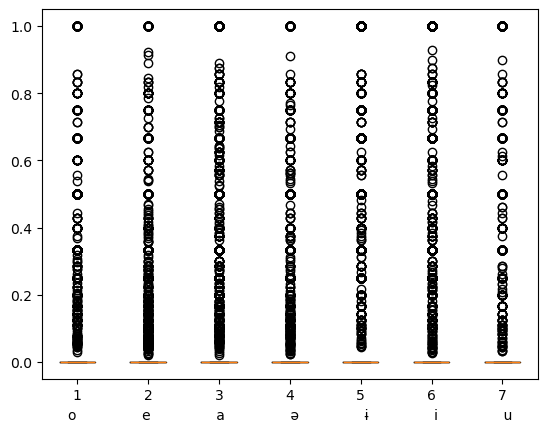

In [86]:
devoicing_rate = {v: list(data[data['V']==v]['devoicing']) for v in vowels}
fig, ax = plt.subplots()
plt.xlabel('               '.join(list(devoicing_rate.keys())))
ax.boxplot([[rate for rate in devoicing_rate[v]] for v in devoicing_rate.keys()])

{'whiskers': [<matplotlib.lines.Line2D at 0x14af38d10>,
 'caps': [<matplotlib.lines.Line2D at 0x14af39280>,
 'boxes': [<matplotlib.lines.Line2D at 0x14af38aa0>,
 'medians': [<matplotlib.lines.Line2D at 0x14af39790>,
 'fliers': [<matplotlib.lines.Line2D at 0x14af39a60>,
 'means': []}

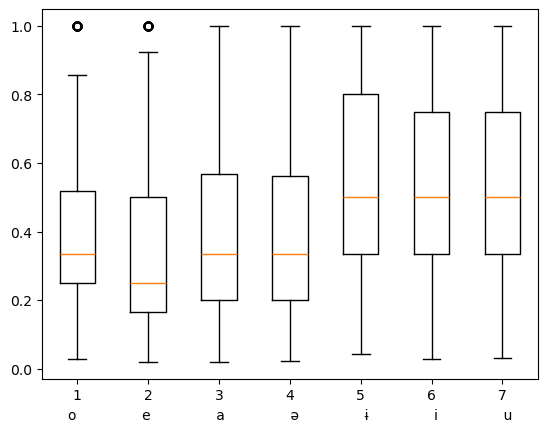

In [85]:
devoicing_rate = {v: list(data[data['V']==v]['devoicing']) for v in vowels}
fig, ax = plt.subplots()
plt.xlabel('               '.join(list(devoicing_rate.keys())))
ax.boxplot([[rate for rate in devoicing_rate[v] if rate>0] for v in devoicing_rate.keys()])

In [97]:
data[data['V'].isin(high_vowels)]['devoiced'].mean()

0.11884372457085286

In [98]:
data[~data['V'].isin(high_vowels)]['devoiced'].mean()

0.04279654597788214

In [99]:
stats.ttest_ind(data[data['V'].isin(high_vowels)]['devoicing'], data[~data['V'].isin(high_vowels)]['devoicing'])

TtestResult(statistic=35.342733296932344, pvalue=4.7229229112050125e-271, df=65411.0)

In [63]:
# 조건 필터링
filtered_data1 = data[
    (data['V'].isin(high_vowels)) &
    (data['pre'].isin(spr_glottis_continuant)) &
    (data['post'].isin(spr_glottis_noncontinuant))
]

filtered_data1

,pre,V,post,length,devoicing,devoiced
237,s,ɨ,tʰ,0.03371,0.00000,False
384,s,i,tʰ,0.03000,1.00000,True
871,s,i,pʰ,0.03741,0.00000,False
940,s,i,pʰ,0.04000,1.00000,True
1210,s,i,pʰ,0.04000,0.66667,True
...,...,...,...,...,...,...
65031,s,ɨ,kʰ,0.03570,1.00000,True
65039,s,ɨ,kʰ,0.03261,1.00000,True
65053,s,ɨ,kʰ,0.03071,0.33333,False
65069,s,ɨ,kʰ,0.02040,0.50000,True


In [65]:
filtered_data2 = data[
    (data['V'].isin(high_vowels)) &
    (~(data['pre'].isin(spr_glottis_continuant)) |
    ~(data['post'].isin(spr_glottis_noncontinuant)))
]

filtered_data2

,pre,V,post,length,devoicing,devoiced
0,l,ɨ,m,0.06000,0.0,False
1,m,ɨ,n,0.10000,0.0,False
7,l,i,m,0.03000,0.0,False
8,m,i,t,0.05686,0.0,False
13,n,ɨ,n,0.13000,0.0,False
...,...,...,...,...,...,...
65403,n,i,k',0.09234,0.0,False
65405,s',u,k,0.05398,0.0,False
65407,tɕ,i,n,0.03000,0.0,False
65408,n,ɨ,ŋ,0.02845,0.0,False


In [66]:
filtered_data2['devoiced'].mean()

0.11142126990367604

In [67]:
filtered_data1['devoiced']

237      False
384       True
871      False
940       True
1210      True
         ...  
65031     True
65039     True
65053    False
65069     True
65113     True
Name: devoiced, Length: 372, dtype: bool

In [68]:
corr, p_value = stats.pearsonr(data['length'], data['devoicing'])
print(f"Pearson correlation: {corr}, p-value: {p_value}")

Pearson correlation: -0.11123217309764949, p-value: 4.102284268606428e-179


In [101]:
from scipy.stats import ttest_ind

# 조건에 맞는 환경: 고모음 & pre = [+spr glottis, +continuant] & post = [+spr glottis, -continuant]
conditioned_data = data[
    (data['V'].isin(high_vowels)) &
    (data['pre'].isin(spr_glottis_continuant)) &
    (data['post'].isin(spr_glottis_noncontinuant))
]

# 조건 외 환경: 모든 행에서 위 조건을 제외
other_data = data[
    (
        (data['V'].isin(high_vowels)) &
        (~(data['pre'].isin(spr_glottis_continuant)) |
        ~(data['post'].isin(spr_glottis_noncontinuant)))
    )
]

# 무성음화 비율 추출
conditioned_devoiced = conditioned_data['devoicing']
other_devoiced = other_data['devoicing']

# 무성음화 비율 평균 계산
conditioned_mean = conditioned_devoiced.mean()
other_mean = other_devoiced.mean()

# 통계적 검정 (독립표본 t-검정)
t_stat, p_value = ttest_ind(conditioned_devoiced, other_devoiced, equal_var=False)

# 결과 정리
comparison_results = {
    'Conditioned Environment Mean': conditioned_mean,
    'Other Environment Mean': other_mean,
    'T-Statistic': t_stat,
    'P-Value': p_value
}

comparison_results


{'Conditioned Environment Mean': 0.5207353494623655,
 'Other Environment Mean': 0.09795436013367409,
 'T-Statistic': 23.077947245721848,
 'P-Value': 4.7488724884796196e-74}

{'whiskers': [<matplotlib.lines.Line2D at 0x14bb484d0>,
 'caps': [<matplotlib.lines.Line2D at 0x14bb48a10>,
 'boxes': [<matplotlib.lines.Line2D at 0x14bb48260>,
 'medians': [<matplotlib.lines.Line2D at 0x14bb48e60>,
 'fliers': [<matplotlib.lines.Line2D at 0x14bb49100>,
 'means': []}

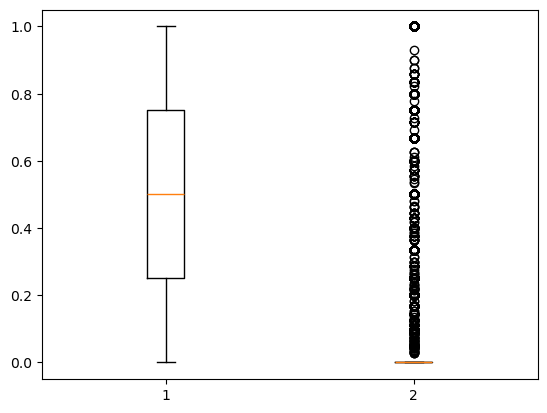

In [102]:
fig, ax = plt.subplots()
ax.boxplot([conditioned_devoiced, other_devoiced])

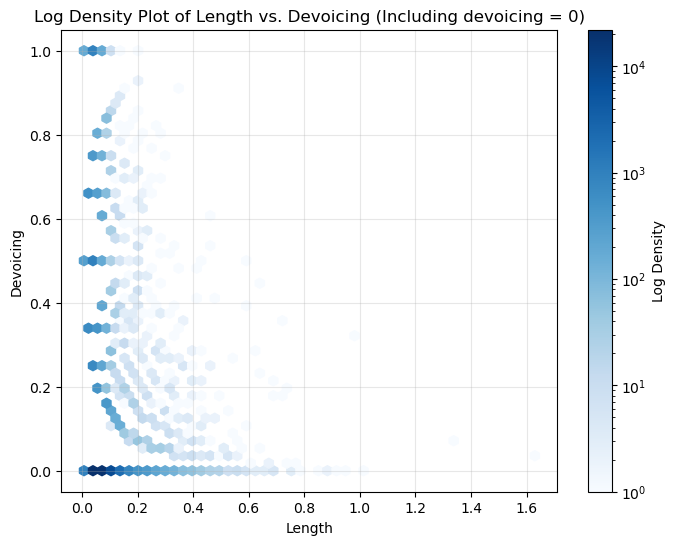

In [70]:
# Create density plot with log scale for all data (including devoicing = 0)
plt.figure(figsize=(8, 6))
plt.hexbin(data['length'], data['devoicing'], gridsize=50, cmap='Blues', mincnt=1, bins='log')
plt.colorbar(label='Log Density')
plt.title("Log Density Plot of Length vs. Devoicing (Including devoicing = 0)")
plt.xlabel("Length")
plt.ylabel("Devoicing")
plt.grid(True, alpha=0.3)
plt.show()

In [71]:
# Calculate IQR to identify outliers for 'length'
Q1 = data['length'].quantile(0.25)
Q3 = data['length'].quantile(0.75)
IQR = Q3 - Q1

# Define lower and upper bounds for outlier detection
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter data to remove outliers
filtered_data_no_outliers = data[(data['length'] >= lower_bound) & (data['length'] <= upper_bound)]

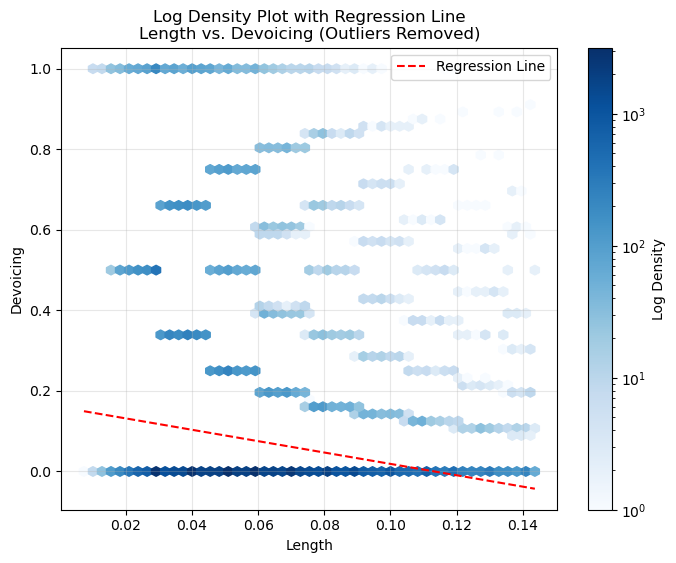

In [72]:
import numpy as np

# Create a scatter density plot with regression line
plt.figure(figsize=(8, 6))

# Create density plot
plt.hexbin(filtered_data_no_outliers['length'], filtered_data_no_outliers['devoicing'], 
           gridsize=50, cmap='Blues', mincnt=1, bins='log')

# Fit a regression line
x = filtered_data_no_outliers['length']
y = filtered_data_no_outliers['devoicing']
coeffs = np.polyfit(x, y, 1)  # Linear regression
reg_line = np.poly1d(coeffs)

# Plot the regression line
x_vals = np.linspace(x.min(), x.max(), 500)
plt.plot(x_vals, reg_line(x_vals), color='red', linestyle='--', label='Regression Line')

# Add colorbar and labels
plt.colorbar(label='Log Density')
plt.title("Log Density Plot with Regression Line\nLength vs. Devoicing (Outliers Removed)")
plt.xlabel("Length")
plt.ylabel("Devoicing")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
